# Notebook 03r — Random Forest Multi-Horizon (REVISI)
**Basis:** `03_random_forest.ipynb` (tidak diubah). Metode dan ruang pencarian tidak berubah (RandomizedSearchCV n_iter=20, TimeSeriesSplit 3 fold, skor neg-RMSE, `random_state=42`).

**Apa yang direvisi dan mengapa:**
- Input diganti ke data revisi (2 node, fitur per segmen, tanpa celah waktu) di `dataset/revisi/`; model dan metrik ke `models/revisi/`.
- File prediksi kini memuat `segmen`, `aktual`, dan `sekarang` (kelembaban saat ini) agar evaluasi status irigasi dan kejadian transisi di 05r dapat dihitung.
- **Baseline persistensi** (prediksi = kelembaban saat ini) ditambahkan sebagai pembanding wajar untuk deret waktu.

In [1]:
# -- CELL 1: Import -----------------------------------------------
import os, json, warnings, joblib, time
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import randint

plt.style.use('seaborn-v0_8-whitegrid')
OUT, MOUT = 'dataset/revisi', 'models/revisi'
os.makedirs(OUT, exist_ok=True); os.makedirs(MOUT, exist_ok=True)
HORIZONS = ['60m', '180m', '360m']
TARGET_MAP = {h: f'target_{h}' for h in HORIZONS}

In [2]:
# -- CELL 2: Fungsi evaluasi ---------------------------------------
def evaluasi(y_true, y_pred, label=''):
    y_true = np.asarray(y_true, dtype=float); y_pred = np.asarray(y_pred, dtype=float)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    r2 = r2_score(y_true, y_pred)
    mape = float(np.mean(np.abs((y_true - y_pred) / (np.abs(y_true) + 1e-8))) * 100)
    if label: print(f'  [{label}] MAE={mae:.4f}  RMSE={rmse:.4f}  R2={r2:.4f}  MAPE={mape:.2f}%')
    return {'MAE': float(mae), 'RMSE': rmse, 'R2': float(r2), 'MAPE': mape}

# -- CELL 3: Ruang pencarian (sama seperti lama) --------------------
param_dist = {
    'n_estimators': randint(80, 201), 'max_depth': randint(8, 18),
    'min_samples_leaf': randint(5, 21), 'max_features': ['sqrt', 'log2', 0.5],
    'min_samples_split': randint(5, 20),
}
N_ITER, N_CV = 20, 3

In [3]:
# -- CELL 4: Training RF per horizon -------------------------------
rf_results = {}
importances_all = {}

for horizon in HORIZONS:
    t0 = time.time()
    target = TARGET_MAP[horizon]
    print(f'\n{"="*55}\n  Random Forest - Horizon {horizon}\n{"="*55}')

    tr = pd.read_csv(f'{OUT}/data_train_{horizon}.csv', parse_dates=['waktu_pembacaan'])
    te = pd.read_csv(f'{OUT}/data_test_{horizon}.csv',  parse_dates=['waktu_pembacaan'])
    with open(f'{MOUT}/feature_cols_{horizon}.json') as f: feat_cols = json.load(f)
    X_tr, y_tr = tr[feat_cols].values, tr[target].values
    X_te, y_te = te[feat_cols].values, te[target].values
    print(f'  train={len(X_tr):,} | test={len(X_te):,} | fitur={len(feat_cols)}')

    search = RandomizedSearchCV(
        RandomForestRegressor(n_jobs=-1, random_state=42, oob_score=False),
        param_distributions=param_dist, n_iter=N_ITER, cv=TimeSeriesSplit(n_splits=N_CV),
        scoring='neg_root_mean_squared_error', n_jobs=-1, random_state=42, verbose=0)
    search.fit(X_tr, y_tr)
    best_params = {k: (v.item() if hasattr(v, 'item') else v) for k, v in search.best_params_.items()}
    cv_rmse = float(-search.best_score_)
    print(f'  Best CV-RMSE: {cv_rmse:.4f} | {best_params}')

    rf = RandomForestRegressor(**best_params, n_jobs=-1, random_state=42, oob_score=True)
    rf.fit(X_tr, y_tr)
    print(f'  OOB score: {rf.oob_score_:.4f}')

    p_tr, p_te = rf.predict(X_tr), rf.predict(X_te)
    m_tr = evaluasi(y_tr, p_tr, f'Train-{horizon}')
    m_te = evaluasi(y_te, p_te, f'Test -{horizon}')
    # Baseline persistensi: prediksi = kelembaban saat ini
    m_pers = evaluasi(y_te, te['kelembaban_tanah_avg'].values, f'Persistensi-{horizon}')

    path = f'{MOUT}/rf_model_{horizon}.pkl'
    joblib.dump(rf, path, compress=3)

    pd.DataFrame({'waktu_pembacaan': te['waktu_pembacaan'], 'segmen': te['segmen'],
                  'aktual': y_te, 'sekarang': te['kelembaban_tanah_avg'], 'prediksi_rf': p_te}
                 ).to_csv(f'{OUT}/prediksi_rf_{horizon}.csv', index=False)

    imp = pd.Series(rf.feature_importances_, index=feat_cols).sort_values(ascending=False)
    importances_all[horizon] = imp
    rf_results[horizon] = {
        'best_params': best_params, 'cv_rmse': cv_rmse, 'oob_score': float(rf.oob_score_),
        'train_metrics': m_tr, 'test_metrics': m_te, 'persistensi_metrics': m_pers,
        'feature_importance_top20': {k: float(v) for k, v in imp.head(20).items()},
        'feature_importance_all': {k: float(v) for k, v in imp.items()},
        'n_train': int(len(X_tr)), 'n_test': int(len(X_te)), 'n_features': len(feat_cols),
        'model_size_mb': float(os.path.getsize(path)/1e6), 'waktu_latih_detik': float(time.time()-t0)}
    print(f'  selesai {time.time()-t0:.0f} detik')

with open(f'{MOUT}/rf_metrics_all.json', 'w') as f: json.dump(rf_results, f, indent=2)
print('\n[OK] rf_metrics_all.json disimpan')


  Random Forest - Horizon 60m
  train=82,474 | test=20,619 | fitur=73
  Best CV-RMSE: 7.1391 | {'max_depth': 13, 'max_features': 'log2', 'min_samples_leaf': 20, 'min_samples_split': 16, 'n_estimators': 100}
  OOB score: 0.9885
  [Train-60m] MAE=0.7130  RMSE=1.7936  R2=0.9901  MAPE=1.13%
  [Test -60m] MAE=1.6892  RMSE=2.7734  R2=0.9567  MAPE=2.67%
  [Persistensi-60m] MAE=1.3807  RMSE=2.9678  R2=0.9504  MAPE=2.27%
  selesai 1417 detik

  Random Forest - Horizon 180m
  train=81,052 | test=20,263 | fitur=73
  Best CV-RMSE: 9.0529 | {'max_depth': 16, 'max_features': 'sqrt', 'min_samples_leaf': 15, 'min_samples_split': 15, 'n_estimators': 121}
  OOB score: 0.9899
  [Train-180m] MAE=0.6654  RMSE=1.6425  R2=0.9917  MAPE=1.06%
  [Test -180m] MAE=2.7605  RMSE=4.2282  R2=0.9004  MAPE=4.45%
  [Persistensi-180m] MAE=2.2738  RMSE=4.0806  R2=0.9072  MAPE=3.79%
  selesai 1331 detik

  Random Forest - Horizon 360m
  train=79,059 | test=19,765 | fitur=73
  Best CV-RMSE: 10.8842 | {'max_depth': 13, 'max

Horizon Model            MAE    RMSE      R2    MAPE
60m     RF             1.689   2.773   0.957    2.67
60m     Persistensi    1.381   2.968   0.950    2.27
180m    RF             2.761   4.228   0.900    4.45
180m    Persistensi    2.274   4.081   0.907    3.79
360m    RF             3.981   5.338   0.844    6.44
360m    Persistensi    3.330   5.203   0.852    5.66


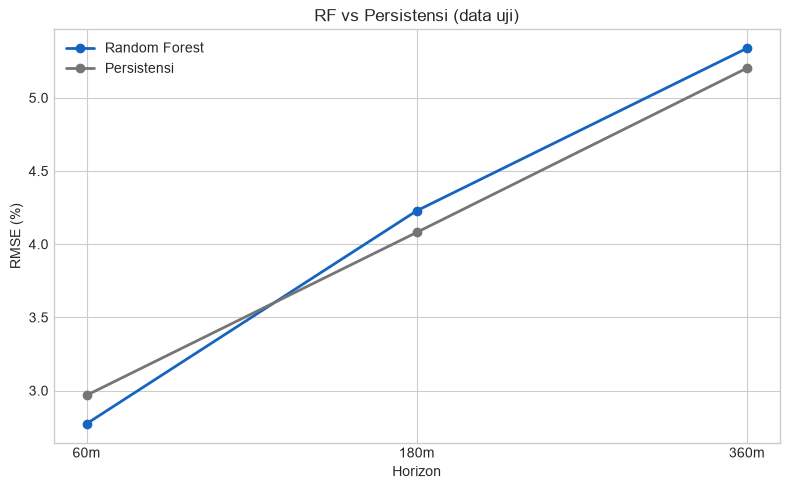

In [4]:
# -- CELL 5: Ringkasan RF vs Persistensi ---------------------------
print(f'{"Horizon":<8}{"Model":<12}{"MAE":>8}{"RMSE":>8}{"R2":>8}{"MAPE":>8}')
for h, r in rf_results.items():
    for nama, k in [('RF', 'test_metrics'), ('Persistensi', 'persistensi_metrics')]:
        m = r[k]; print(f'{h:<8}{nama:<12}{m["MAE"]:>8.3f}{m["RMSE"]:>8.3f}{m["R2"]:>8.3f}{m["MAPE"]:>8.2f}')

fig, ax = plt.subplots(figsize=(8, 5))
for nama, k, c in [('Random Forest', 'test_metrics', '#1565C0'), ('Persistensi', 'persistensi_metrics', '#757575')]:
    ax.plot(HORIZONS, [rf_results[h][k]['RMSE'] for h in HORIZONS], 'o-', label=nama, color=c, lw=2)
ax.set_xlabel('Horizon'); ax.set_ylabel('RMSE (%)'); ax.set_title('RF vs Persistensi (data uji)'); ax.legend()
plt.tight_layout(); plt.savefig(f'{OUT}/plot_rf_vs_persistensi.png', dpi=150); plt.show()

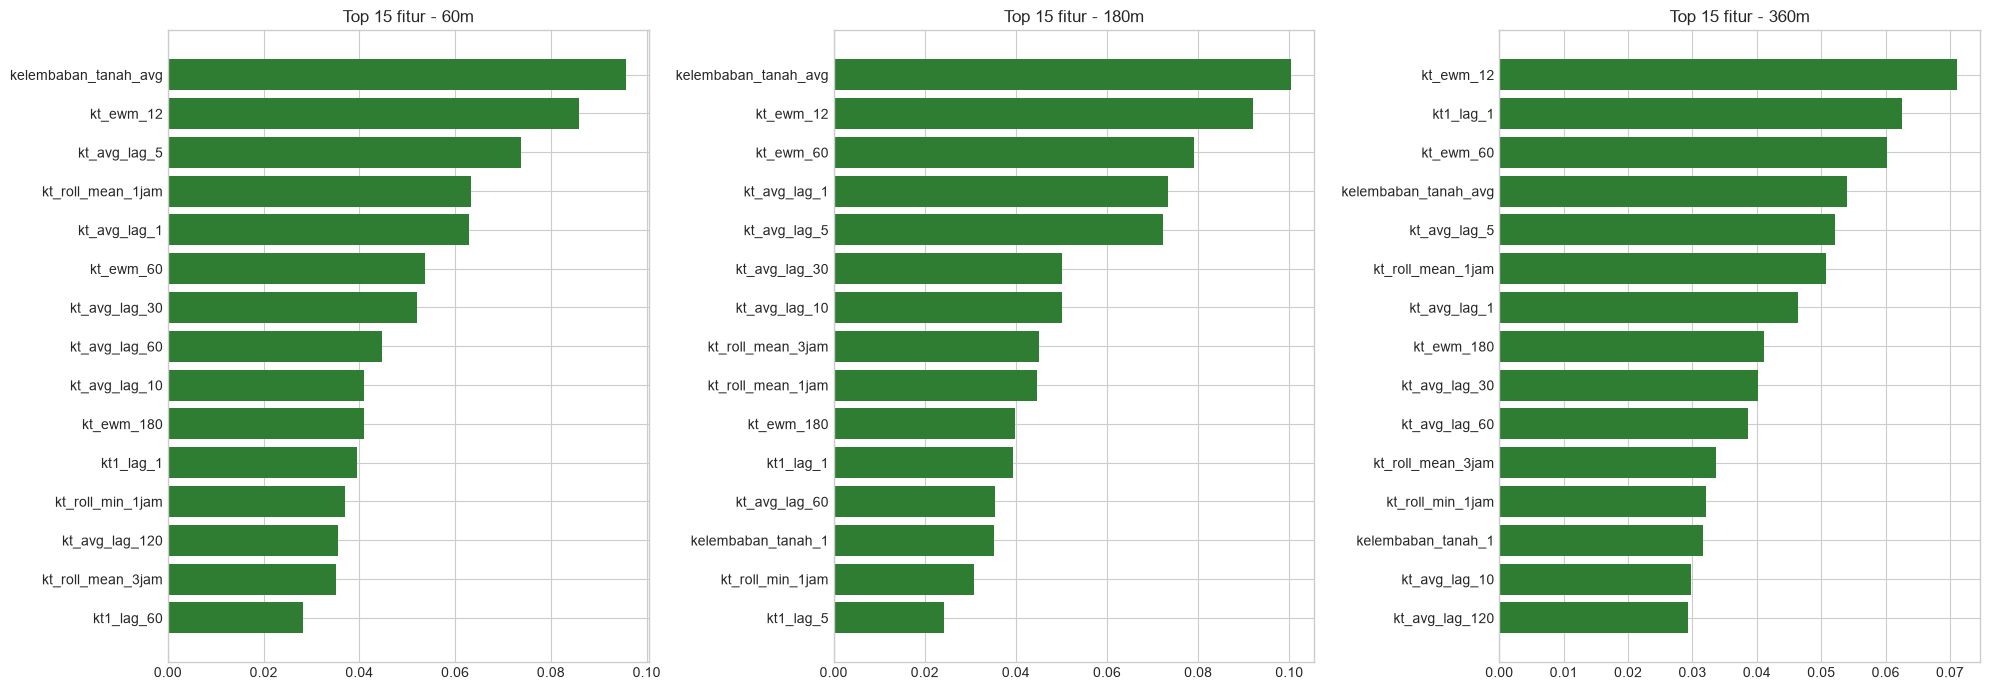

kelembaban_tanah_avg    0.095625
kt_ewm_12               0.085826
kt_avg_lag_5            0.073796
kt_roll_mean_1jam       0.063312
kt_avg_lag_1            0.062881
kt_ewm_60               0.053636
kt_avg_lag_30           0.051985
kt_avg_lag_60           0.044724
kt_avg_lag_10           0.040972
kt_ewm_180              0.040965


In [5]:
# -- CELL 6: Feature importance (semua horizon) ---------------------
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, h in zip(axes, HORIZONS):
    s = importances_all[h].head(15)[::-1]
    ax.barh(s.index, s.values, color='#2E7D32'); ax.set_title(f'Top 15 fitur - {h}')
plt.tight_layout(); plt.savefig(f'{OUT}/plot_rf_feature_importance_revisi.png', dpi=150); plt.show()
print(importances_all['60m'].head(10).to_string())

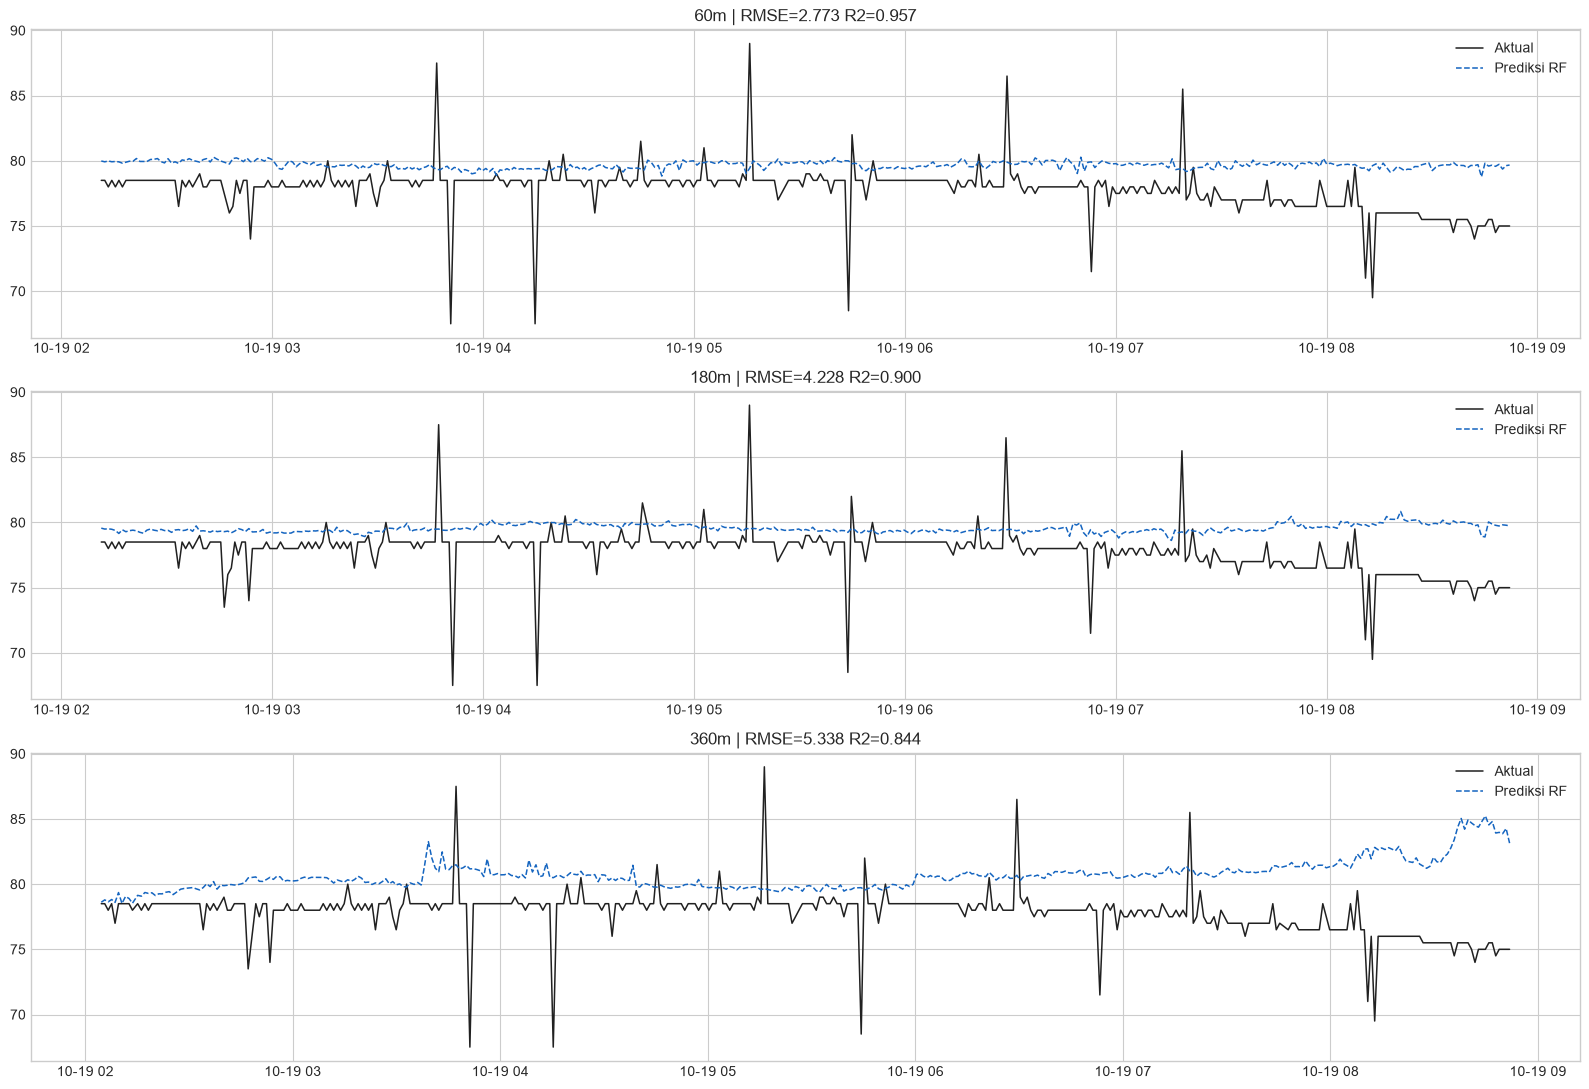

Lanjut ke 04r_xgboost_lightgbm.ipynb


In [6]:
# -- CELL 7: Prediksi vs aktual (400 sampel terakhir per horizon) ----
fig, axes = plt.subplots(3, 1, figsize=(16, 11))
for ax, h in zip(axes, HORIZONS):
    d = pd.read_csv(f'{OUT}/prediksi_rf_{h}.csv', parse_dates=['waktu_pembacaan']).tail(400)
    wv = d['waktu_pembacaan'] + pd.Timedelta(minutes=int(h[:-1]))      # waktu valid prediksi (t+h)
    ax.plot(wv, d['aktual'], color='#212121', lw=1.1, label='Aktual')
    ax.plot(wv, d['prediksi_rf'], color='#1565C0', lw=1.1, ls='--', label='Prediksi RF')
    ax.set_title(f'{h} | RMSE={rf_results[h]["test_metrics"]["RMSE"]:.3f} R2={rf_results[h]["test_metrics"]["R2"]:.3f}')
    ax.legend()
plt.tight_layout(); plt.savefig(f'{OUT}/plot_rf_prediksi_revisi.png', dpi=150); plt.show()
print('Lanjut ke 04r_xgboost_lightgbm.ipynb')